# B2 - Convolutional Neural Network (image classification)

**Dataset:** Fashion-MNIST (60k train / 10k test, 28x28 grayscale, 10 classes).

We train the same CNN **with and without data augmentation** to measure its effect, and plot accuracy/loss curves.

In [1]:
import json, time, random
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

def save_result(name, d):
    """Persist metrics so the final comparison report can read them."""
    p = OUT / "results.json"
    r = json.loads(p.read_text()) if p.exists() else {}
    r[name] = d
    p.write_text(json.dumps(r, indent=2))

def plot_curves(h, title, fname):
    """Training-vs-validation loss and accuracy/metric curves."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(title + " - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val")
    ax[1].set_title(title + " - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(OUT / fname, dpi=130); plt.show()


Device: cuda


In [2]:
def run_epoch(model, loader, loss_fn, opt=None):
    """One pass over loader. Trains if opt is given, else evaluates."""
    train = opt is not None
    model.train(train)
    tot_loss, preds, ys = 0.0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(yb)
            preds.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return tot_loss / len(ys), accuracy_score(ys, preds), preds, ys

def fit(model, train_dl, val_dl, epochs, lr=1e-3, weight_decay=0.0, patience=None, verbose=True):
    """Adam + cross-entropy; keeps the best-val-loss weights. Returns history and train time."""
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state, bad = 1e9, None, 0
    t0 = time.time()
    for ep in range(epochs):
        tl, ta, _, _ = run_epoch(model, train_dl, loss_fn, opt)
        vl, va, _, _ = run_epoch(model, val_dl, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        if vl < best:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose: print(f"ep {ep+1:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if patience and bad >= patience:
            print("early stop"); break
    model.load_state_dict(best_state)
    return h, time.time() - t0

def report(model, loader, names=None, average="binary"):
    _, _, p, y = run_epoch(model, loader, nn.CrossEntropyLoss())
    r = dict(accuracy=accuracy_score(y, p),
             precision=precision_score(y, p, average=average, zero_division=0),
             recall=recall_score(y, p, average=average, zero_division=0),
             f1=f1_score(y, p, average=average, zero_division=0))
    return r, p, y

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)


  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:01, 216kB/s]

  0%|          | 65.5k/26.4M [00:00<02:01, 217kB/s]

  0%|          | 98.3k/26.4M [00:00<02:02, 216kB/s]

  1%|          | 229k/26.4M [00:00<00:55, 471kB/s] 

  2%|▏         | 459k/26.4M [00:00<00:30, 841kB/s]

... (190 outputs left out)

100%|██████████| 4.42M/4.42M [00:01<00:00, 2.23MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 10.4MB/s]

60000 10000 ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


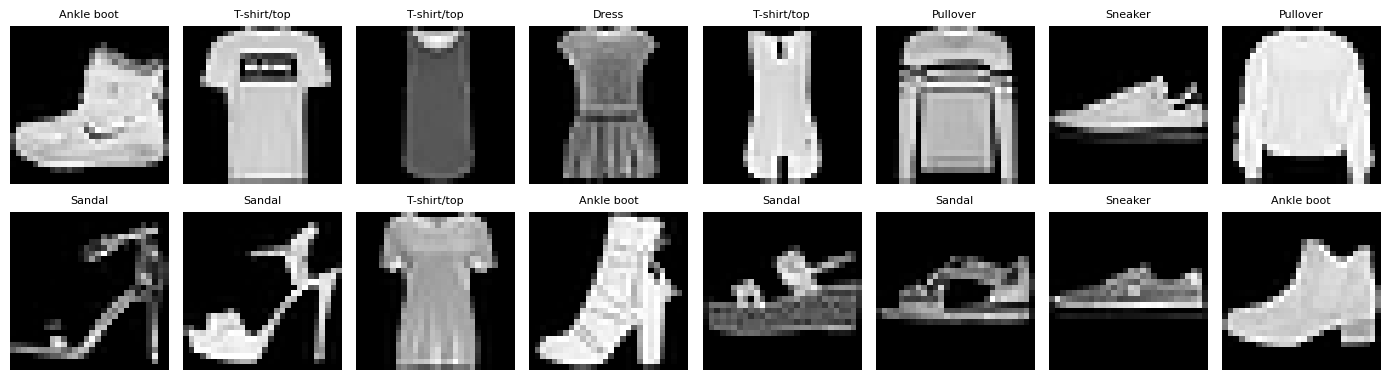

In [3]:
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, random_split, Dataset

root = "data"
raw_tr = torchvision.datasets.FashionMNIST(root, train=True, download=True)
raw_te = torchvision.datasets.FashionMNIST(root, train=False, download=True)
classes = raw_tr.classes
print(len(raw_tr), len(raw_te), classes)

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, i in zip(ax.ravel(), range(16)):
    a.imshow(raw_tr[i][0], cmap="gray"); a.set_title(classes[raw_tr[i][1]], fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "cnn_samples.png", dpi=120); plt.show()

## 1. Data pipelines
Augmentation (train only): random crop with padding, small rotation, horizontal flip (clothing is left/right symmetric). Validation = 5k images held out of the training set; test = official 10k.

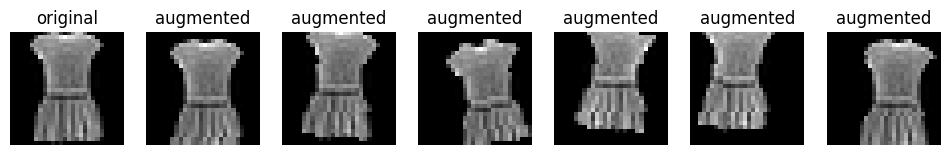

In [4]:
MEAN, STD = 0.2860, 0.3530
norm = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
aug = T.Compose([T.RandomCrop(28, padding=3), T.RandomRotation(10), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(MEAN, STD)])

class Tfm(Dataset):
    """Wraps a subset of raw PIL images and applies a transform on the fly."""
    def __init__(self, base, idx, tfm): self.base, self.idx, self.tfm = base, idx, tfm
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, y = self.base[self.idx[i]]
        return self.tfm(img), y

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(raw_tr), generator=g).tolist()
tr_idx, va_idx = perm[:55000], perm[55000:]
kw = dict(batch_size=128, num_workers=0)
train_plain = DataLoader(Tfm(raw_tr, tr_idx, norm), shuffle=True, **kw)
train_aug   = DataLoader(Tfm(raw_tr, tr_idx, aug),  shuffle=True, **kw)
val_dl  = DataLoader(Tfm(raw_tr, va_idx, norm), **kw)
test_dl = DataLoader(Tfm(raw_te, list(range(len(raw_te))), norm), **kw)

# show what augmentation does to one image
fig, ax = plt.subplots(1, 7, figsize=(12, 2))
ax[0].imshow(raw_tr[3][0], cmap="gray"); ax[0].set_title("original")
for a in ax[1:]:
    a.imshow(aug(raw_tr[3][0]).squeeze(), cmap="gray"); a.set_title("augmented")
for a in ax: a.axis("off")
plt.savefig(OUT / "cnn_augmentation.png", dpi=120); plt.show()

## 2. Architecture
Three conv blocks (Conv-BN-ReLU x2 -> MaxPool -> Dropout) with 32/64/128 filters, then a dense head. BatchNorm stabilises training; dropout combats over-fitting.

In [5]:
def block(i, o, p):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.MaxPool2d(2), nn.Dropout(p))

class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(1, 32, 0.1), block(32, 64, 0.2), block(64, 128, 0.3))  # 28->14->7->3
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 3 * 3, 256), nn.ReLU(), nn.Dropout(0.4), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

print(CNN()); print("params:", n_params(CNN()))

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (

## 3. Train: without vs. with augmentation

In [6]:
torch.manual_seed(SEED)
m_plain = CNN().to(device)
h_plain, t_plain = fit(m_plain, train_plain, val_dl, epochs=15, lr=1e-3)

ep 01 | train loss 0.4648 acc 0.8295 | val loss 0.2899 acc 0.8898


ep 02 | train loss 0.2959 acc 0.8910 | val loss 0.2643 acc 0.8980


ep 03 | train loss 0.2551 acc 0.9073 | val loss 0.2309 acc 0.9112


ep 04 | train loss 0.2318 acc 0.9155 | val loss 0.2319 acc 0.9164


ep 05 | train loss 0.2130 acc 0.9217 | val loss 0.2136 acc 0.9182


ep 06 | train loss 0.1983 acc 0.9266 | val loss 0.1980 acc 0.9262


... (5 outputs left out)

ep 12 | train loss 0.1463 acc 0.9459 | val loss 0.1858 acc 0.9338


ep 13 | train loss 0.1371 acc 0.9482 | val loss 0.1693 acc 0.9340


ep 14 | train loss 0.1319 acc 0.9514 | val loss 0.1792 acc 0.9372


ep 15 | train loss 0.1254 acc 0.9537 | val loss 0.1762 acc 0.9370


In [7]:
torch.manual_seed(SEED)
m_aug = CNN().to(device)
h_aug, t_aug = fit(m_aug, train_aug, val_dl, epochs=15, lr=1e-3)

ep 01 | train loss 0.6575 acc 0.7557 | val loss 0.4458 acc 0.8426


ep 02 | train loss 0.4477 acc 0.8348 | val loss 0.3460 acc 0.8750


ep 03 | train loss 0.3911 acc 0.8562 | val loss 0.3257 acc 0.8804


ep 04 | train loss 0.3614 acc 0.8680 | val loss 0.3048 acc 0.8870


ep 05 | train loss 0.3447 acc 0.8731 | val loss 0.2655 acc 0.9036


ep 06 | train loss 0.3266 acc 0.8797 | val loss 0.2626 acc 0.8984


... (5 outputs left out)

ep 12 | train loss 0.2725 acc 0.9007 | val loss 0.2209 acc 0.9172


ep 13 | train loss 0.2682 acc 0.9039 | val loss 0.2543 acc 0.9050


ep 14 | train loss 0.2652 acc 0.9042 | val loss 0.2138 acc 0.9218


ep 15 | train loss 0.2548 acc 0.9078 | val loss 0.2329 acc 0.9172


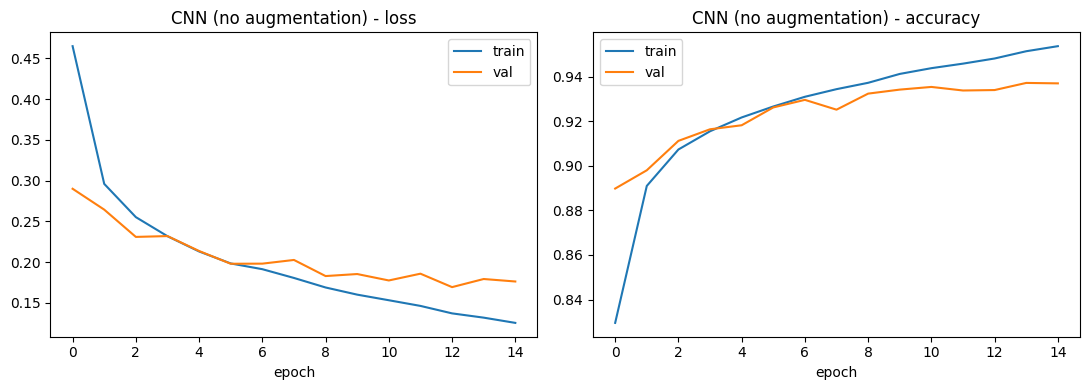

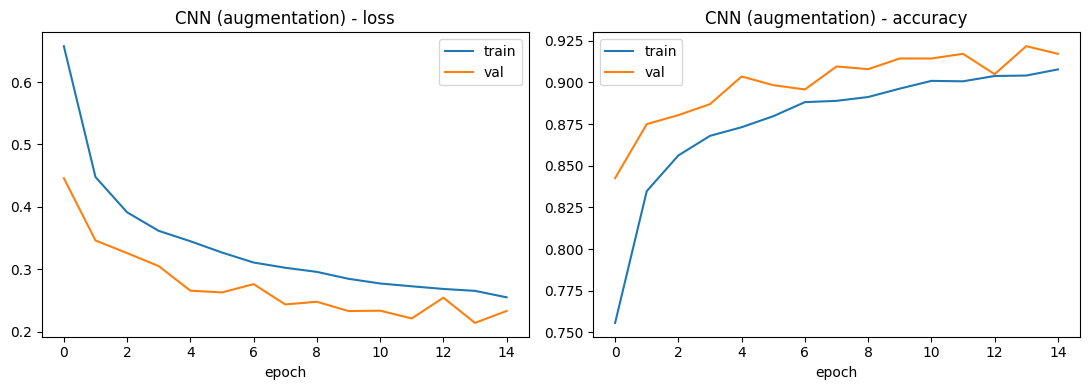

In [8]:
plot_curves(h_plain, "CNN (no augmentation)", "cnn_curves_plain.png")
plot_curves(h_aug, "CNN (augmentation)", "cnn_curves_aug.png")

## 4. Test-set evaluation (macro-averaged precision/recall)

In [9]:
out = {}
for name, m, t in [("no_aug", m_plain, t_plain), ("aug", m_aug, t_aug)]:
    r, p, y = report(m, test_dl, average="macro")
    r.update(train_time_s=t, params=n_params(m)); out[name] = r
    print(name, {k: round(v, 4) for k, v in r.items()})
pd_res = __import__("pandas").DataFrame(out).T; display(pd_res)
save_result("CNN", dict(out["aug"], without_aug=out["no_aug"]))

no_aug {'accuracy': 0.9371, 'precision': 0.9369, 'recall': 0.9371, 'f1': 0.9366, 'train_time_s': 108.5557, 'params': 585066}


aug {'accuracy': 0.923, 'precision': 0.923, 'recall': 0.923, 'f1': 0.9226, 'train_time_s': 198.903, 'params': 585066}


,accuracy,precision,recall,f1,train_time_s,params
no_aug,0.9371,0.936919,0.9371,0.936606,108.555664,585066.0
aug,0.9230,0.922982,0.9230,0.922626,198.903033,585066.0


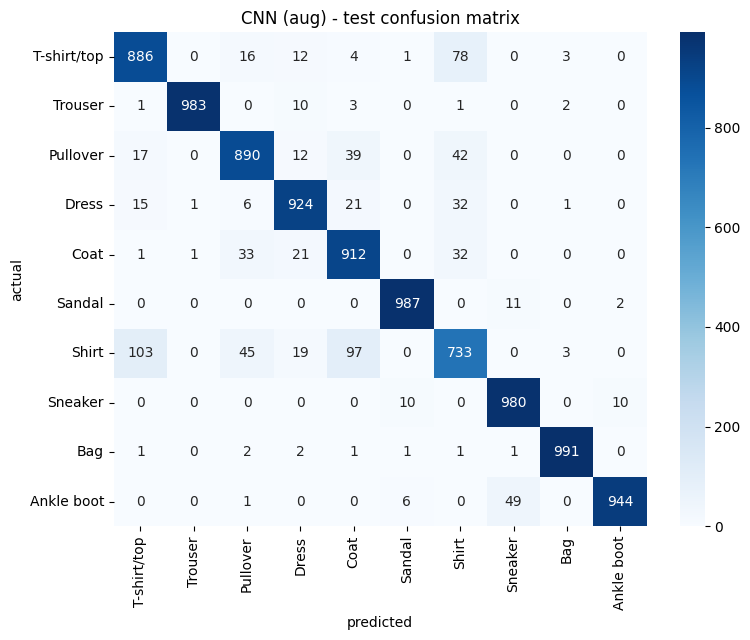

              precision    recall  f1-score   support

 T-shirt/top      0.865     0.886     0.875      1000
     Trouser      0.998     0.983     0.990      1000
    Pullover      0.896     0.890     0.893      1000
       Dress      0.924     0.924     0.924      1000
        Coat      0.847     0.912     0.878      1000
      Sandal      0.982     0.987     0.985      1000
       Shirt      0.798     0.733     0.764      1000
     Sneaker      0.941     0.980     0.960      1000
         Bag      0.991     0.991     0.991      1000
  Ankle boot      0.987     0.944     0.965      1000

    accuracy                          0.923     10000
   macro avg      0.923     0.923     0.923     10000
weighted avg      0.923     0.923     0.923     10000



In [10]:
import seaborn as sns
r, pred, ytrue = report(m_aug, test_dl, average="macro")
plt.figure(figsize=(8, 6.5))
sns.heatmap(confusion_matrix(ytrue, pred), annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("CNN (aug) - test confusion matrix"); plt.xlabel("predicted"); plt.ylabel("actual"); plt.tight_layout()
plt.savefig(OUT / "cnn_confusion.png", dpi=130); plt.show()

from sklearn.metrics import classification_report
print(classification_report(ytrue, pred, target_names=classes, digits=3))

## 5. Discussion
- **Without augmentation** the model starts to over-fit after ~epoch 6: train accuracy keeps rising (~95.5%) while validation flattens (~93.7%) and val loss stops improving.
- **With augmentation** there is no over-fitting - validation stays *above* training (the train images are harder because they are distorted, and dropout is active), and both curves are still rising at epoch 15.
- In this 15-epoch budget the augmented model scores ~1.5 points **lower** on the test set (see table). Augmentation acts as a regulariser that trades fitting speed for generalisation; it pays off with longer training or smaller/noisier datasets. Fashion-MNIST images are centred and uniformly oriented, so rotation/crop also introduce variation the test set never contains. Next steps: train the augmented model for 30-40 epochs, or use milder augmentation (flip + small shift only).
- Most confusion is among Shirt / T-shirt / Pullover / Coat - visually similar upper-body garments - not between dissimilar classes.
- Convolutions share weights and exploit spatial locality, giving far fewer parameters than a dense net on 784 pixels.